# Gradient Boosting Trees paso a paso con `DecisionTreeRegressor`

Este notebook construye la idea de **Gradient Boosting Trees (GBT)** manualmente, usando únicamente `DecisionTreeRegressor` como learner base.

La meta es entender el mecanismo:

$$
\hat y^{(m)} = \hat y^{(m-1)} + \alpha h_m(x)
$$

donde:

- $\hat y^{(m-1)}$ es la predicción anterior
- $h_m(x)$ es un árbol entrenado sobre los **residuales**
- $\alpha$ es el **learning rate**

## Idea intuitiva

En vez de entrenar un árbol para predecir directamente el precio de la casa en cada iteración, hacemos esto:

1. Empezamos con una predicción muy simple: el promedio del precio
2. Calculamos los errores del modelo actual
3. Entrenamos un árbol para predecir esos errores
4. Corregimos la predicción anterior con una parte de esa predicción del error
5. Repetimos

En otras palabras:

> **predicción nueva = predicción anterior + learning rate × predicción de residuales**

Usaremos un ejemplo de **precio de casas** con variables comunes:

- metros cuadrados
- recámaras
- baños
- antigüedad
- distancia al centro

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 1. Crear un dataset sintético de casas

Generaremos datos ficticios pero razonables. El precio dependerá de varias variables y además meteremos ruido para que el problema se parezca más a uno real.

In [2]:
n = 150

metros = np.random.randint(60, 260, size=n)
recamaras = np.random.randint(1, 6, size=n)
banos = np.random.randint(1, 5, size=n)
antiguedad = np.random.randint(0, 35, size=n)
dist_centro = np.random.uniform(1, 20, size=n)

precio = (
    12000 * metros
    + 180000 * recamaras
    + 140000 * banos
    - 18000 * antiguedad
    - 50000 * dist_centro
    + 3500 * metros * (recamaras >= 4)
    - 2500 * (dist_centro ** 2)
    + np.random.normal(0, 180000, size=n)
)

df = pd.DataFrame({
    "metros": metros,
    "recamaras": recamaras,
    "banos": banos,
    "antiguedad": antiguedad,
    "dist_centro": dist_centro,
    "precio": precio
})

df.head().round(2)

,metros,recamaras,banos,antiguedad,dist_centro,precio
0,162,1,3,4,16.62,752833.70
1,239,4,3,3,14.42,3637610.84
2,152,5,2,5,2.55,3437044.36
3,74,4,3,31,2.61,1529024.29
4,166,5,2,29,19.75,1638832.77


## 2. Explorar una muestra de los datos

In [3]:
df.sample(10, random_state=1).round(2)

,metros,recamaras,banos,antiguedad,dist_centro,precio
14,163,2,3,25,11.61,1350203.33
98,100,3,2,23,18.95,-347690.06
75,113,4,4,28,18.72,764383.53
16,190,1,1,8,18.22,807601.55
131,163,3,1,24,18.18,617016.65
56,149,1,1,3,4.57,2024206.05
141,86,1,2,10,10.35,751191.30
44,190,1,1,32,14.22,846852.93
29,81,1,3,11,6.43,771430.08
120,194,3,2,11,1.55,2818037.84


## 3. Separar variables explicativas y variable objetivo

In [4]:
X = df[["metros", "recamaras", "banos", "antiguedad", "dist_centro"]]
y = df["precio"].values

## 4. Paso 0: predicción inicial

En regresión con error cuadrático medio, la mejor predicción constante inicial es el promedio:

$$
F_0(x) = \bar y
$$

Eso significa que al inicio **todas las casas reciben la misma predicción**.

In [5]:
y_mean = y.mean()
pred_0 = np.repeat(y_mean, len(y))

tabla_0 = df.copy()
tabla_0["pred_0"] = pred_0
tabla_0["residual_1"] = y - pred_0

tabla_0.head(10).round(2)

,metros,recamaras,banos,antiguedad,dist_centro,precio,pred_0,residual_1
0,162,1,3,4,16.62,752833.70,1599131.09,-846297.39
1,239,4,3,3,14.42,3637610.84,1599131.09,2038479.76
2,152,5,2,5,2.55,3437044.36,1599131.09,1837913.28
3,74,4,3,31,2.61,1529024.29,1599131.09,-70106.80
4,166,5,2,29,19.75,1638832.77,1599131.09,39701.69
5,131,5,2,34,8.11,1970981.25,1599131.09,371850.17
6,248,3,2,15,8.04,2881794.45,1599131.09,1282663.37
7,80,5,2,12,16.44,620273.18,1599131.09,-978857.91
8,162,4,2,29,19.00,990040.32,1599131.09,-609090.76
9,181,5,1,18,19.73,1460595.52,1599131.09,-138535.57


### Interpretación

Los residuales del primer paso son:

$$
r_i^{(1)} = y_i - \hat y_i^{(0)}
$$

Si el residual es positivo, la casa valía más de lo que predijimos.

Si el residual es negativo, la casa valía menos de lo que predijimos.

In [6]:
mse_0 = mean_squared_error(y, pred_0)
rmse_0 = np.sqrt(mse_0)

pd.DataFrame({
    "modelo": ["Solo promedio"],
    "MSE": [mse_0],
    "RMSE": [rmse_0]
}).round(2)

,modelo,MSE,RMSE
0,Solo promedio,1.099767e+12,1048697.94


## 5. Primer árbol: aprender residuales

Ahora entrenamos un `DecisionTreeRegressor` para predecir los residuales del paso anterior.

Ese árbol ya **no** aprende el precio de la casa. Aprende el **error** del modelo.

In [7]:
alpha = 0.1

tree_1 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_1.fit(X, tabla_0["residual_1"])

h1 = tree_1.predict(X)
pred_1 = pred_0 + alpha * h1

tabla_1 = df.copy()
tabla_1["pred_0"] = pred_0
tabla_1["residual_1"] = y - pred_0
tabla_1["tree_1_pred"] = h1
tabla_1["pred_1"] = pred_1
tabla_1["residual_2"] = y - pred_1

tabla_1.head(10).round(2)

,metros,recamaras,banos,antiguedad,dist_centro,precio,pred_0,residual_1,tree_1_pred,pred_1,residual_2
0,162,1,3,4,16.62,752833.70,1599131.09,-846297.39,-613339.77,1537797.11,-784963.41
1,239,4,3,3,14.42,3637610.84,1599131.09,2038479.76,1797685.17,1778899.60,1858711.24
2,152,5,2,5,2.55,3437044.36,1599131.09,1837913.28,466067.89,1645737.87,1791306.49
3,74,4,3,31,2.61,1529024.29,1599131.09,-70106.80,466067.89,1645737.87,-116713.59
4,166,5,2,29,19.75,1638832.77,1599131.09,39701.69,-613339.77,1537797.11,101035.67
5,131,5,2,34,8.11,1970981.25,1599131.09,371850.17,-613339.77,1537797.11,433184.15
6,248,3,2,15,8.04,2881794.45,1599131.09,1282663.37,427170.28,1641848.11,1239946.34
7,80,5,2,12,16.44,620273.18,1599131.09,-978857.91,-613339.77,1537797.11,-917523.93
8,162,4,2,29,19.00,990040.32,1599131.09,-609090.76,-613339.77,1537797.11,-547756.78
9,181,5,1,18,19.73,1460595.52,1599131.09,-138535.57,-613339.77,1537797.11,-77201.59


La actualización fue:

$$
F_1(x) = F_0(x) + \alpha h_1(x)
$$

donde:

- $F_0(x)$ era el promedio
- $h_1(x)$ es el árbol que predice residuales
- $\alpha$ es el learning rate

O sea:

$$
\text{predicción nueva} = \text{predicción anterior} + \alpha \times \text{predicción del error}
$$

In [8]:
mse_1 = mean_squared_error(y, pred_1)
rmse_1 = np.sqrt(mse_1)

pd.DataFrame({
    "modelo": ["Solo promedio", "Promedio + árbol 1"],
    "MSE": [mse_0, mse_1],
    "RMSE": [rmse_0, rmse_1]
}).round(2)

,modelo,MSE,RMSE
0,Solo promedio,1.099767e+12,1048697.94
1,Promedio + árbol 1,9.736377e+11,986730.83


## 6. Visualizar el primer árbol

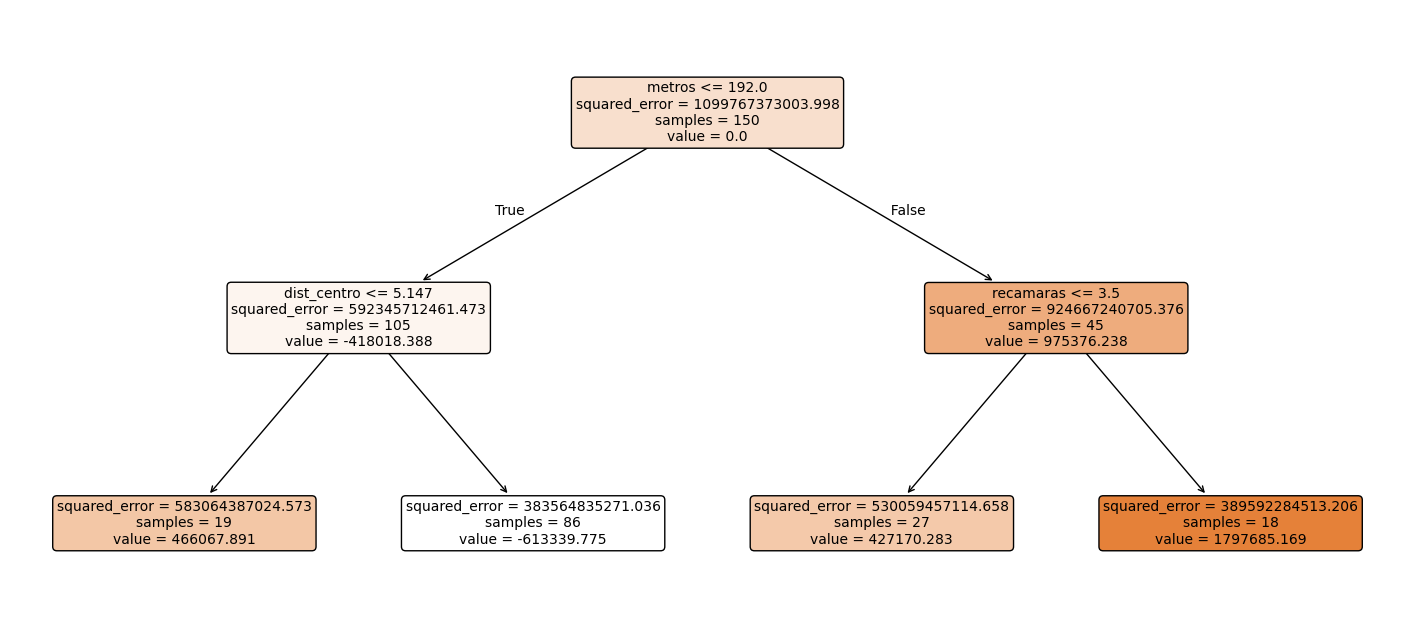

In [9]:
plt.figure(figsize=(18, 8))
plot_tree(
    tree_1,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

## 7. Segundo árbol: volver a aprender lo que sigue faltando

Después del primer árbol, todavía hay error.

Entonces calculamos nuevos residuales:

$$
r_i^{(2)} = y_i - \hat y_i^{(1)}
$$

y entrenamos un segundo árbol sobre esos nuevos residuales.

In [10]:
tree_2 = DecisionTreeRegressor(max_depth=2, random_state=43)
tree_2.fit(X, tabla_1["residual_2"])

h2 = tree_2.predict(X)
pred_2 = pred_1 + alpha * h2

tabla_2 = df.copy()
tabla_2["pred_1"] = pred_1
tabla_2["residual_2"] = y - pred_1
tabla_2["tree_2_pred"] = h2
tabla_2["pred_2"] = pred_2
tabla_2["residual_3"] = y - pred_2

tabla_2.head(10).round(2)

,metros,recamaras,banos,antiguedad,dist_centro,precio,pred_1,residual_2,tree_2_pred,pred_2,residual_3
0,162,1,3,4,16.62,752833.70,1537797.11,-784963.41,-775740.74,1460223.03,-707389.33
1,239,4,3,3,14.42,3637610.84,1778899.60,1858711.24,296893.31,1808588.93,1829021.91
2,152,5,2,5,2.55,3437044.36,1645737.87,1791306.49,15769.45,1647314.82,1789729.54
3,74,4,3,31,2.61,1529024.29,1645737.87,-116713.59,15769.45,1647314.82,-118290.53
4,166,5,2,29,19.75,1638832.77,1537797.11,101035.67,-775740.74,1460223.03,178609.74
5,131,5,2,34,8.11,1970981.25,1537797.11,433184.15,15769.45,1539374.05,431607.20
6,248,3,2,15,8.04,2881794.45,1641848.11,1239946.34,1541776.10,1796025.72,1085768.73
7,80,5,2,12,16.44,620273.18,1537797.11,-917523.93,-775740.74,1460223.03,-839949.85
8,162,4,2,29,19.00,990040.32,1537797.11,-547756.78,-775740.74,1460223.03,-470182.71
9,181,5,1,18,19.73,1460595.52,1537797.11,-77201.59,-775740.74,1460223.03,372.48


In [11]:
mse_2 = mean_squared_error(y, pred_2)
rmse_2 = np.sqrt(mse_2)

pd.DataFrame({
    "modelo": [
        "Solo promedio",
        "Promedio + árbol 1",
        "Promedio + árbol 1 + árbol 2"
    ],
    "MSE": [mse_0, mse_1, mse_2],
    "RMSE": [rmse_0, rmse_1, rmse_2]
}).round(2)

,modelo,MSE,RMSE
0,Solo promedio,1.099767e+12,1048697.94
1,Promedio + árbol 1,9.736377e+11,986730.83
2,Promedio + árbol 1 + árbol 2,8.680744e+11,931705.11


## 8. Función manual de Gradient Boosting

Ahora encapsulamos el algoritmo para correr muchas iteraciones.

In [12]:
def gradient_boosting_manual(X, y, n_estimators=20, learning_rate=0.1, max_depth=2):
    pred = np.repeat(np.mean(y), len(y))
    pred_history = [pred.copy()]
    mse_history = [mean_squared_error(y, pred)]
    rmse_history = [np.sqrt(mse_history[-1])]
    residual_history = [y - pred]
    trees = []
    updates = []

    for m in range(n_estimators):
        residual = y - pred

        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=100 + m)
        tree.fit(X, residual)

        update = tree.predict(X)
        pred = pred + learning_rate * update

        trees.append(tree)
        updates.append(update)
        pred_history.append(pred.copy())
        residual_history.append(y - pred)
        mse_history.append(mean_squared_error(y, pred))
        rmse_history.append(np.sqrt(mse_history[-1]))

    return {
        "pred_final": pred,
        "trees": trees,
        "updates": updates,
        "pred_history": pred_history,
        "residual_history": residual_history,
        "mse_history": mse_history,
        "rmse_history": rmse_history
    }

## 9. Ejecutar el algoritmo manual

In [13]:
resultado = gradient_boosting_manual(
    X, y,
    n_estimators=30,
    learning_rate=0.1,
    max_depth=2
)

tabla_metricas = pd.DataFrame({
    "iteracion": np.arange(len(resultado["mse_history"])),
    "MSE": resultado["mse_history"],
    "RMSE": resultado["rmse_history"]
})

tabla_metricas.head(10).round(2)

,iteracion,MSE,RMSE
0,0,1.099767e+12,1048697.94
1,1,9.736377e+11,986730.83
2,2,8.680744e+11,931705.11
3,3,7.753446e+11,880536.52
4,4,6.990431e+11,836087.99
5,5,6.331782e+11,795724.96
6,6,5.688093e+11,754194.49
7,7,5.160508e+11,718366.79
8,8,4.720391e+11,687051.05
9,9,4.339150e+11,658722.28


## 10. Ver cómo disminuye el error con las iteraciones

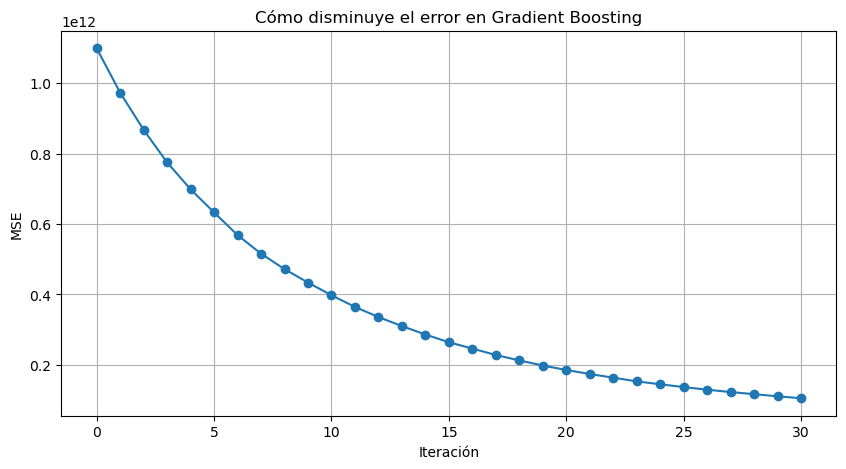

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(tabla_metricas["iteracion"], tabla_metricas["MSE"], marker="o")
plt.xlabel("Iteración")
plt.ylabel("MSE")
plt.title("Cómo disminuye el error en Gradient Boosting")
plt.grid(True)
plt.show()

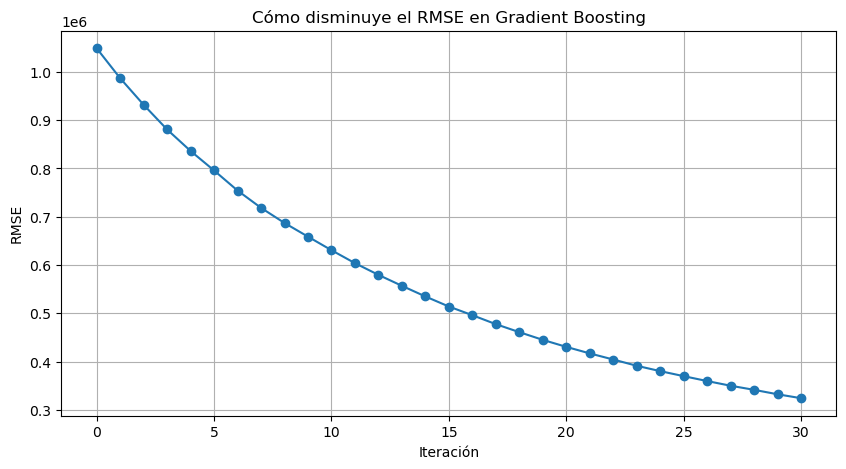

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(tabla_metricas["iteracion"], tabla_metricas["RMSE"], marker="o")
plt.xlabel("Iteración")
plt.ylabel("RMSE")
plt.title("Cómo disminuye el RMSE en Gradient Boosting")
plt.grid(True)
plt.show()

## 11. Comparar precio real vs predicción final

In [16]:
df_resultado = df.copy()
df_resultado["pred_final"] = resultado["pred_final"]
df_resultado["error_final"] = df_resultado["precio"] - df_resultado["pred_final"]

df_resultado.head(10).round(2)

,metros,recamaras,banos,antiguedad,dist_centro,precio,pred_final,error_final
0,162,1,3,4,16.62,752833.70,862510.35,-109676.65
1,239,4,3,3,14.42,3637610.84,2858667.53,778943.31
2,152,5,2,5,2.55,3437044.36,2672413.41,764630.95
3,74,4,3,31,2.61,1529024.29,1707207.18,-178182.89
4,166,5,2,29,19.75,1638832.77,1225439.81,413392.96
5,131,5,2,34,8.11,1970981.25,1850046.69,120934.57
6,248,3,2,15,8.04,2881794.45,2730278.99,151515.47
7,80,5,2,12,16.44,620273.18,659537.78,-39264.60
8,162,4,2,29,19.00,990040.32,1225439.81,-235399.49
9,181,5,1,18,19.73,1460595.52,1581414.74,-120819.23


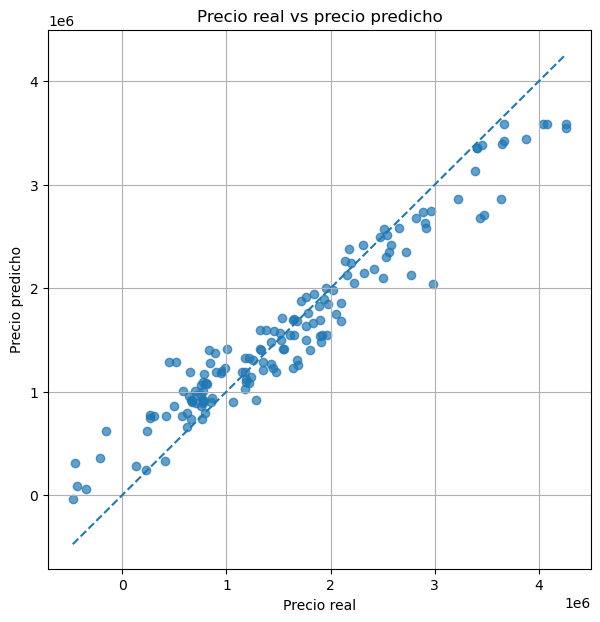

In [17]:
plt.figure(figsize=(7, 7))
plt.scatter(df_resultado["precio"], df_resultado["pred_final"], alpha=0.7)
lims = [
    min(df_resultado["precio"].min(), df_resultado["pred_final"].min()),
    max(df_resultado["precio"].max(), df_resultado["pred_final"].max())
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Precio real")
plt.ylabel("Precio predicho")
plt.title("Precio real vs precio predicho")
plt.grid(True)
plt.show()

## 12. Seguir una sola casa paso a paso

Esta parte es muy útil didácticamente.

Seleccionamos una casa y vemos cómo cambia su predicción en cada iteración.

In [18]:
idx = 0  # cambia este índice para ver otra casa

x_casa = X.iloc[[idx]]
fila_casa = df.iloc[[idx]].round(2)
y_real = y[idx]

print("Casa seleccionada:")
display(fila_casa)

pred_inicial = y.mean()
print(f"Predicción inicial (promedio): {pred_inicial:,.2f}")

pred_casa = pred_inicial
pred_global = np.repeat(y.mean(), len(y))

historial_casa = [{
    "iteracion": 0,
    "update_arbol": 0.0,
    "prediccion_casa": pred_casa
}]

for m in range(5):
    residual_global = y - pred_global

    tree = DecisionTreeRegressor(max_depth=2, random_state=200 + m)
    tree.fit(X, residual_global)

    update_global = tree.predict(X)
    update_casa = tree.predict(x_casa)[0]

    pred_casa = pred_casa + alpha * update_casa
    pred_global = pred_global + alpha * update_global

    historial_casa.append({
        "iteracion": m + 1,
        "update_arbol": update_casa,
        "prediccion_casa": pred_casa
    })

historial_casa_df = pd.DataFrame(historial_casa)
historial_casa_df.round(2)

Casa seleccionada:


,metros,recamaras,banos,antiguedad,dist_centro,precio
0,162,1,3,4,16.62,752833.7


Predicción inicial (promedio): 1,599,131.09


,iteracion,update_arbol,prediccion_casa
0,0,0.00,1599131.09
1,1,-613339.77,1537797.11
2,2,-775740.74,1460223.03
3,3,-816496.28,1378573.41
4,4,-467267.14,1331846.69
5,5,-704198.43,1261426.85


In [19]:
print(f"Precio real de la casa: {y_real:,.2f}")
print(f"Predicción final tras 5 iteraciones: {historial_casa_df.iloc[-1]['prediccion_casa']:,.2f}")

Precio real de la casa: 752,833.70
Predicción final tras 5 iteraciones: 1,261,426.85


## 13. Descomposición explícita de la predicción

El modelo final se puede escribir como:

$$
F_M(x) = \bar y + \alpha h_1(x) + \alpha h_2(x) + \cdots + \alpha h_M(x)
$$

Eso significa que la predicción final es:

- el promedio inicial
- más una primera corrección
- más una segunda corrección
- más una tercera corrección
- etc.

La idea importante es esta:

> **cada árbol nuevo intenta explicar lo que todavía no ha sido explicado**

In [20]:
iteraciones_a_mostrar = 5

descomp = pd.DataFrame({
    "iteracion": np.arange(iteraciones_a_mostrar + 1),
    "prediccion_casa": historial_casa_df["prediccion_casa"]
})

descomp["cambio_vs_iteracion_anterior"] = descomp["prediccion_casa"].diff().fillna(0)
descomp.round(2)

,iteracion,prediccion_casa,cambio_vs_iteracion_anterior
0,0,1599131.09,0.00
1,1,1537797.11,-61333.98
2,2,1460223.03,-77574.07
3,3,1378573.41,-81649.63
4,4,1331846.69,-46726.71
5,5,1261426.85,-70419.84


## 14. Función de predicción para nuevas casas

Construimos una función que use los árboles guardados para predecir nuevas observaciones.

In [21]:
def predecir_gbm_manual(X_new, y_train_mean, trees, learning_rate=0.1):
    pred = np.repeat(y_train_mean, len(X_new)).astype(float)
    for tree in trees:
        pred += learning_rate * tree.predict(X_new)
    return pred

In [22]:
nueva_casa = pd.DataFrame([{
    "metros": 180,
    "recamaras": 4,
    "banos": 3,
    "antiguedad": 8,
    "dist_centro": 6.5
}])

pred_nueva = predecir_gbm_manual(
    nueva_casa,
    y_train_mean=y.mean(),
    trees=resultado["trees"],
    learning_rate=0.1
)

nueva_casa["prediccion_precio"] = pred_nueva
nueva_casa.round(2)

,metros,recamaras,banos,antiguedad,dist_centro,prediccion_precio
0,180,4,3,8,6.5,2696657.86


## 15. Resumen conceptual

### Algoritmo

1. Inicializar con el promedio:

$$
F_0(x) = \bar y
$$

2. Para cada iteración $m$:

   a. Calcular residuales:

$$
r_i^{(m)} = y_i - \hat y_i^{(m-1)}
$$

   b. Entrenar un árbol sobre esos residuales

   c. Actualizar:

$$
F_m(x) = F_{m-1}(x) + \alpha h_m(x)
$$

### Frase mental correcta

> **Gradient Boosting = promedio inicial + suma de árboles que corrigen errores**

## 16. Conexión con descenso en gradiente

En este notebook usamos MSE, así que los pseudoresiduos coinciden con los residuales clásicos.

En el caso general, Gradient Boosting usa el **gradiente negativo** de la función de pérdida:

$$
r_{im} = - \left[\frac{\partial L(y_i, F(x_i))}{\partial F(x_i)} \right]_{F = F_{m-1}}
$$

Por eso se llama **Gradient Boosting**:

- no solo corrige errores
- corrige en la dirección del gradiente que más reduce la pérdida

Pero en regresión con MSE, eso se ve exactamente como “aprender residuales”.

## 17. Ejercicio sugerido para alumnos

Prueba cambiar uno o varios de estos parámetros y observa qué pasa:

- `alpha`
- `max_depth`
- `n_estimators`

Preguntas útiles:

1. ¿Qué pasa si `alpha` es muy grande?
2. ¿Qué pasa si el árbol es muy profundo?
3. ¿Qué pasa si aumentas mucho el número de iteraciones?
4. ¿En qué se parece esto al descenso en gradiente?
5. ¿Por qué cada árbol no predice directamente el precio final?